In [ ]:
import pandas as pd
import gurobipy as gp
from gurobipy import GRB

df = pd.read_csv("single_machine.csv")

p = df["processing_time"].tolist()
d = df["due_date"].tolist()
w = df["weight"].tolist()

n = len(p)
jobs = range(n)
positions = range(n)
H = sum(p)

# APDV – Assignment Position Decision Variables

## Idea
APDV assigns jobs to positions in the schedule.

**Question:** Which job should be assigned to each position?

## Decision Variable

$$
u_{jk}=
\begin{cases}
1, & \text{if job } j \text{ is assigned to position } k\\
0, & \text{otherwise}
\end{cases}
$$

## Constraints

Each position receives exactly one job:

$$
\sum_{j=1}^{n} u_{jk}=1 \qquad \forall k
$$

Each job is assigned exactly once:

$$
\sum_{k=1}^{n} u_{jk}=1 \qquad \forall j
$$

## Objective

$$
\min \sum_{j=1}^{n} w_jT_j
$$

## Main Advantage

- Simple formulation
- Small number of constraints
- Usually the fastest method

## Main Question

**Which job should occupy each position in the schedule?**

```

```



In [ ]:
model = gp.Model("APDV_Weighted_Tardiness")
model.setParam("TimeLimit", 300)
model.setParam("MIPGap", 0.01)

u = model.addVars(jobs, positions, vtype=GRB.BINARY, name="u")
Cpos = model.addVars(positions, lb=0, name="Cpos")
Cjob = model.addVars(jobs, lb=0, name="Cjob")
T = model.addVars(jobs, lb=0, name="T")

for k in positions:
    model.addConstr(gp.quicksum(u[j,k] for j in jobs) == 1)

for j in jobs:
    model.addConstr(gp.quicksum(u[j,k] for k in positions) == 1)

model.addConstr(Cpos[0] == gp.quicksum(p[j] * u[j,0] for j in jobs))

for k in range(1,n):
    model.addConstr(
        Cpos[k] == Cpos[k-1] + gp.quicksum(p[j] * u[j,k] for j in jobs)
    )

for j in jobs:
    for k in positions:
        model.addGenConstrIndicator(
            u[j,k],
            True,
            Cjob[j] == Cpos[k]
        )

for j in jobs:
    model.addConstr(T[j] >= Cjob[j] - d[j])

model.setObjective(
    gp.quicksum(w[j] * T[j] for j in jobs),
    GRB.MINIMIZE
)

model.optimize()

schedule = []
for k in positions:
    for j in jobs:
        if u[j,k].X > 0.5:
            schedule.append(j+1)

print("APDV Schedule:", schedule)
print("Objective:", model.ObjVal)

apdv_result = {
    "Formulation": "APDV",
    "Objective": model.ObjVal,
    "Runtime": model.Runtime,
    "Nodes": model.NodeCount,
    "Variables": model.NumVars,
    "Constraints": model.NumConstrs,
    "Gap": model.MIPGap,
    "Schedule": schedule
}

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i7-6600U CPU @ 2.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  300
MIPGap  0.01

Optimize a model with 60 rows, 270 columns and 734 nonzeros (Min)
Model fingerprint: 0x77c2a3fe
Model has 15 linear objective coefficients
Model has 225 simple general constraints
  225 INDICATOR
Variable types: 45 continuous, 225 integer (225 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+01]
  Objective range  [1e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]
  GenCon coe range [1e+00, 1e+00]

Presolve added 225 rows and 225 columns
Presolve time: 0.03s
Presolved: 285 rows, 495 columns, 1439 nonzeros
Presolved model has 225 SOS constraint(s)
Variable types: 255 continuous, 

# LOV – Linear Ordering Variables

## Idea

LOV determines the order between every pair of jobs.

**Question:** Which job comes before which job?

## Decision Variable

$$
\delta_{ij}=
\begin{cases}
1, & \text{if job } i \text{ is processed before job } j\\
0, & \text{otherwise}
\end{cases}
$$

## Constraints

Pairwise ordering:

$$
\delta_{ij}+\delta_{ji}=1
\qquad \forall i<j
$$

Transitivity:

$$
\delta_{ij}+\delta_{jk}+\delta_{ki}\le 2
\qquad \forall i,j,k
$$

## Objective

$$
\min \sum_{j=1}^{n} w_jT_j
$$

## Main Advantage

- Direct precedence representation
- Easy interpretation

## Main Disadvantage

- Large number of transitivity constraints

## Main Question

**Which job should be processed before another job?**

In [ ]:
model = gp.Model("LOV_Weighted_Tardiness")
model.setParam("TimeLimit", 300)
model.setParam("MIPGap", 0.01)

delta = model.addVars(jobs, jobs, vtype=GRB.BINARY, name="delta")
C = model.addVars(jobs, lb=0, name="C")
T = model.addVars(jobs, lb=0, name="T")

for i in jobs:
    model.addConstr(delta[i,i] == 0)

for i in jobs:
    for j in jobs:
        if i < j:
            model.addConstr(delta[i,j] + delta[j,i] == 1)

for i in jobs:
    for j in jobs:
        for k in jobs:
            if i != j and j != k and i != k:
                model.addConstr(
                    delta[i,j] + delta[j,k] + delta[k,i] <= 2
                )

for j in jobs:
    model.addConstr(
        C[j] == p[j] + gp.quicksum(p[i] * delta[i,j] for i in jobs if i != j)
    )

for j in jobs:
    model.addConstr(T[j] >= C[j] - d[j])

model.setObjective(
    gp.quicksum(w[j] * T[j] for j in jobs),
    GRB.MINIMIZE
)

model.optimize()

score = {}
for i in jobs:
    score[i] = sum(delta[i,j].X for j in jobs if i != j)

schedule = sorted(jobs, key=lambda i: score[i], reverse=True)
schedule = [j+1 for j in schedule]

print("LOV Schedule:", schedule)
print("Objective:", model.ObjVal)

lov_result = {
    "Formulation": "LOV",
    "Objective": model.ObjVal,
    "Runtime": model.Runtime,
    "Nodes": model.NodeCount,
    "Variables": model.NumVars,
    "Constraints": model.NumConstrs,
    "Gap": model.MIPGap,
    "Schedule": schedule
}

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i7-6600U CPU @ 2.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  300
MIPGap  0.01

Optimize a model with 2880 rows, 255 columns and 8670 nonzeros (Min)
Model fingerprint: 0x2df274b0
Model has 15 linear objective coefficients
Variable types: 30 continuous, 225 integer (225 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+01]
  Objective range  [1e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]

Found heuristic solution: objective 2821.0000000
Presolve removed 1955 rows and 135 columns
Presolve time: 0.03s
Presolved: 925 rows, 120 columns, 2955 nonzeros
Variable types: 0 continuous, 120 integer (105 binary)

Root relaxation: objective 0.000000e+00, 252 iteration

# TIV – Time Indexed Variables

## Idea

TIV determines the exact start time of each job.

**Question:** At what time should each job start?

## Decision Variable

$$
x_{jt}=
\begin{cases}
1, & \text{if job } j \text{ starts at time } t\\
0, & \text{otherwise}
\end{cases}
$$

## Time Horizon

$$
H=\sum_{j=1}^{n} p_j
$$

## Constraints

Each job starts exactly once:

$$
\sum_{t=0}^{H} x_{jt}=1
\qquad \forall j
$$

Machine capacity:

$$
\sum \text{Active Jobs} \le 1
$$

## Objective

$$
\min \sum_{j=1}^{n} w_jT_j
$$

## Main Advantage

- Strong formulation
- Easy to include due dates and release dates

## Main Disadvantage

- Very large number of variables

$$
O(nH)
$$

## Main Question

**At what time should each job start?**

In [ ]:
model = gp.Model("TIV_Weighted_Tardiness")
model.setParam("TimeLimit", 300)
model.setParam("MIPGap", 0.01)

start_times = {
    j: range(H - p[j] + 1)
    for j in jobs
}

x = {}

for j in jobs:
    for t in start_times[j]:
        x[j,t] = model.addVar(vtype=GRB.BINARY, name=f"x_{j}_{t}")

model.update()

C = model.addVars(jobs, lb=0, name="C")
T = model.addVars(jobs, lb=0, name="T")

for j in jobs:
    model.addConstr(
        gp.quicksum(x[j,t] for t in start_times[j]) == 1
    )

for tau in range(H):
    model.addConstr(
        gp.quicksum(
            x[j,t]
            for j in jobs
            for t in start_times[j]
            if t <= tau < t + p[j]
        ) <= 1
    )

for j in jobs:
    model.addConstr(
        C[j] == gp.quicksum(
            (t + p[j]) * x[j,t]
            for t in start_times[j]
        )
    )

for j in jobs:
    model.addConstr(T[j] >= C[j] - d[j])

model.setObjective(
    gp.quicksum(w[j] * T[j] for j in jobs),
    GRB.MINIMIZE
)

model.optimize()

starts = []

for j in jobs:
    for t in start_times[j]:
        if x[j,t].X > 0.5:
            starts.append((t, j+1))

starts.sort()
schedule = [job for t, job in starts]

print("TIV Schedule:", schedule)
print("Objective:", model.ObjVal)

tiv_result = {
    "Formulation": "TIV",
    "Objective": model.ObjVal,
    "Runtime": model.Runtime,
    "Nodes": model.NodeCount,
    "Variables": model.NumVars,
    "Constraints": model.NumConstrs,
    "Gap": model.MIPGap,
    "Schedule": schedule
}

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i7-6600U CPU @ 2.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  300
MIPGap  0.01

Optimize a model with 320 rows, 3895 columns and 76862 nonzeros (Min)
Model fingerprint: 0xf52d109b
Model has 15 linear objective coefficients
Variable types: 30 continuous, 3865 integer (3865 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+02]
  Objective range  [1e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]

Presolve removed 2 rows and 0 columns
Presolve time: 0.12s
Presolved: 318 rows, 3895 columns, 76825 nonzeros
Variable types: 0 continuous, 3895 integer (3865 binary)
Found heuristic solution: objective 1957.0000000

Root relaxation: objective 0.000000e+00, 1834 iterat

# CTV – Completion Time Variables

## Idea

CTV models completion times directly.

**Question:** What should be the completion time of each job?

## Decision Variables

Completion time:

$$
C_j
$$

Precedence variable:

$$
Y_{ij}=
\begin{cases}
1, & \text{if job } i \text{ is processed before job } j\\
0, & \text{otherwise}
\end{cases}
$$

## Constraints

Pairwise ordering:

$$
Y_{ij}+Y_{ji}=1
\qquad \forall i<j
$$

Transitivity:

$$
Y_{ij}+Y_{jk}+Y_{ki}\le 2
$$

Completion time relationship:

$$
C_j \ge C_i+p_j
\qquad \text{if } Y_{ij}=1
$$

## Objective

$$
\min \sum_{j=1}^{n} w_jT_j
$$

## Main Advantage

- Direct completion time modeling

## Main Disadvantage

- Often the slowest formulation

## Main Question

**What should be the completion time of each job?**

In [ ]:
model = gp.Model("CTV_Weighted_Tardiness_Indicator")
model.setParam("TimeLimit", 300)
model.setParam("MIPGap", 0.01)

Y = model.addVars(jobs, jobs, vtype=GRB.BINARY, name="Y")
C = model.addVars(jobs, lb=0, name="C")
T = model.addVars(jobs, lb=0, name="T")

for i in jobs:
    model.addConstr(Y[i,i] == 0)

for i in jobs:
    for j in jobs:
        if i < j:
            model.addConstr(Y[i,j] + Y[j,i] == 1)

for i in jobs:
    for j in jobs:
        for k in jobs:
            if i != j and j != k and i != k:
                model.addConstr(
                    Y[i,j] + Y[j,k] + Y[k,i] <= 2
                )

for j in jobs:
    model.addConstr(C[j] >= p[j])

for i in jobs:
    for j in jobs:
        if i != j:
            model.addGenConstrIndicator(
                Y[i,j],
                True,
                C[j] >= C[i] + p[j]
            )

for j in jobs:
    model.addConstr(T[j] >= C[j] - d[j])

model.setObjective(
    gp.quicksum(w[j] * T[j] for j in jobs),
    GRB.MINIMIZE
)

model.optimize()

score = {}
for i in jobs:
    score[i] = sum(Y[i,j].X for j in jobs if i != j)

schedule = sorted(jobs, key=lambda i: score[i], reverse=True)
schedule = [j+1 for j in schedule]

print("CTV Schedule:", schedule)
print("Objective:", model.ObjVal)

ctv_result = {
    "Formulation": "CTV",
    "Objective": model.ObjVal,
    "Runtime": model.Runtime,
    "Nodes": model.NodeCount,
    "Variables": model.NumVars,
    "Constraints": model.NumConstrs,
    "Gap": model.MIPGap,
    "Schedule": schedule
}

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) i7-6600U CPU @ 2.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Non-default parameters:
TimeLimit  300
MIPGap  0.01

Optimize a model with 2880 rows, 255 columns and 8460 nonzeros (Min)
Model fingerprint: 0x3f30e4ee
Model has 15 linear objective coefficients
Model has 210 simple general constraints
  210 INDICATOR
Variable types: 30 continuous, 225 integer (225 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]
  GenCon rhs range [2e+00, 4e+01]
  GenCon coe range [1e+00, 1e+00]

Presolve added 0 rows and 195 columns
Presolve removed 1640 rows and 0 columns
Presolve time: 0.01s
Presolved: 1240 rows, 450 columns, 3600 nonzer

In [ ]:
results = [
    apdv_result,
    lov_result,
    ctv_result,
    tiv_result
]

df_results = pd.DataFrame(results)

display(df_results)

df_results.to_csv("weighted_tardiness_four_methods.csv", index=False)

,Formulation,Objective,Runtime,Nodes,Variables,Constraints,Gap,Schedule
0,APDV,316.0,4.171,1374.0,270,60,0.000000,"[1, 10, 7, 14, 6, 9, 2, 15, 8, 5, 11, 3, 4, 12..."
1,LOV,316.0,8.201,6384.0,255,2880,0.000000,"[6, 1, 15, 10, 9, 7, 2, 5, 8, 14, 11, 3, 4, 12..."
2,CTV,316.0,300.024,750413.0,255,2880,0.911392,"[3, 6, 8, 9, 1, 2, 10, 7, 15, 5, 14, 11, 4, 12..."
3,TIV,316.0,4.430,1.0,3895,320,0.000000,"[9, 6, 2, 1, 10, 14, 7, 3, 5, 15, 8, 11, 4, 12..."


# Results Analysis

The four formulations (APDV, LOV, CTV, and TIV) were tested on the same 15-job weighted tardiness instance.

## Objective Value

All formulations obtained the same objective value:

$$
\sum_{j=1}^{n} w_jT_j = 316
$$

This confirms that all formulations solved the same scheduling problem and produced an optimal solution with identical total weighted tardiness.

Although the schedules are different, the objective value is identical. This indicates the existence of multiple optimal schedules.

---

## Runtime Comparison

| Formulation | Runtime (s) |
|------------|------------|
| APDV | 4.171 |
| LOV | 8.201 |
| TIV | 4.430 |
| CTV | 300.024 |

APDV was the fastest formulation.

LOV required approximately twice the runtime of APDV due to the large number of transitivity constraints.

TIV also performed well despite having a large number of variables.

CTV was the slowest formulation and reached the imposed time limit of 300 seconds.

---

## Variables and Constraints

| Formulation | Variables | Constraints |
|------------|------------|------------|
| APDV | 270 | 60 |
| LOV | 255 | 2880 |
| CTV | 255 | 2880 |
| TIV | 3895 | 320 |

### APDV

APDV contains a small number of constraints and therefore provides a compact formulation.

### LOV

LOV contains a large number of transitivity constraints:

$$
O(n^3)
$$

which increases computational complexity.

### CTV

CTV also contains transitivity constraints and precedence relationships, making the model difficult to solve.

### TIV

TIV contains many time-indexed variables:

$$
O(nH)
$$

where

$$
H=\sum p_j
$$

This explains the large number of variables.

---

## Branch-and-Bound Nodes

| Formulation | Nodes |
|------------|------------|
| APDV | 1374 |
| LOV | 6384 |
| CTV | 750413 |
| TIV | 1 |

The number of explored nodes reflects the difficulty of proving optimality.

TIV solved the problem directly at the root node.

CTV required exploration of:

$$
750413
$$

nodes, indicating a significantly harder search process.

---

## Optimality Gap

| Formulation | Gap |
|------------|------------|
| APDV | 0.00% |
| LOV | 0.00% |
| TIV | 0.00% |
| CTV | 91.14% |

APDV, LOV, and TIV proved optimality.

CTV reached the time limit before proving optimality and therefore retained a large optimality gap.

---

## Schedule Comparison

The schedules obtained by the formulations are different.

This is expected because the weighted tardiness problem may have multiple optimal solutions.

As long as the objective value remains equal:

$$
316
$$

all schedules are considered optimal.

Therefore, objective value is more important than the exact sequence when comparing formulations.

---

## Overall Ranking

Based on computational performance:

$$
\text{APDV} \succ \text{TIV} \succ \text{LOV} \succ \text{CTV}
$$

where:

- APDV achieved the best overall performance.
- TIV performed surprisingly well despite its large number of variables.
- LOV required additional runtime because of transitivity constraints.
- CTV was the most computationally challenging formulation.

---

## Conclusion

The results demonstrate that different mathematical formulations of the same scheduling problem can produce dramatically different computational performance.

Among the tested formulations, APDV provided the best balance between model size, runtime, and solution quality, making it the most effective formulation for the considered weighted tardiness scheduling problem.

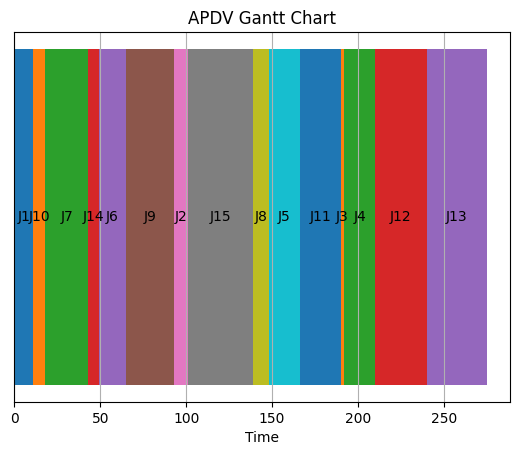

,Job,Start,Duration,Completion
0,1,0,11,11
1,10,11,7,18
2,7,18,25,43
3,14,43,6,49
4,6,49,16,65
5,9,65,28,93
6,2,93,8,101
7,15,101,38,139
8,8,139,9,148
9,5,148,18,166


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

schedule = apdv_result["Schedule"]

start = 0
rows = []

for job in schedule:
    j = job - 1
    duration = p[j]
    completion = start + duration

    rows.append([job, start, duration, completion])

    plt.barh(0, duration, left=start)
    plt.text(start + duration/2, 0, f"J{job}", ha="center", va="center")

    start = completion

plt.title("APDV Gantt Chart")
plt.xlabel("Time")
plt.yticks([])
plt.grid(axis="x")
plt.show()

apdv_gantt = pd.DataFrame(rows, columns=["Job", "Start", "Duration", "Completion"])
display(apdv_gantt)

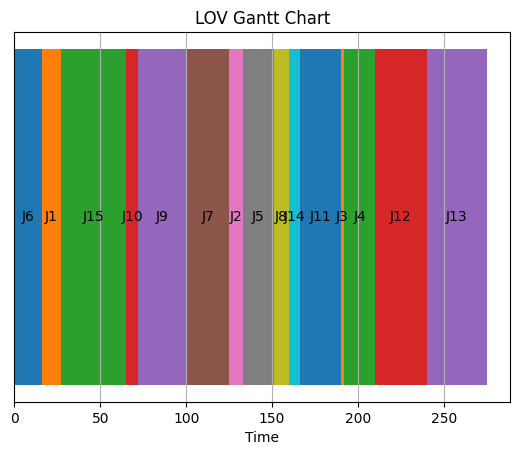

,Job,Start,Duration,Completion
0,6,0,16,16
1,1,16,11,27
2,15,27,38,65
3,10,65,7,72
4,9,72,28,100
5,7,100,25,125
6,2,125,8,133
7,5,133,18,151
8,8,151,9,160
9,14,160,6,166


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

schedule = lov_result["Schedule"]

start = 0
rows = []

for job in schedule:
    j = job - 1
    duration = p[j]
    completion = start + duration

    rows.append([job, start, duration, completion])

    plt.barh(0, duration, left=start)
    plt.text(start + duration/2, 0, f"J{job}", ha="center", va="center")

    start = completion

plt.title("LOV Gantt Chart")
plt.xlabel("Time")
plt.yticks([])
plt.grid(axis="x")
plt.show()

lov_gantt = pd.DataFrame(rows, columns=["Job", "Start", "Duration", "Completion"])
display(lov_gantt)

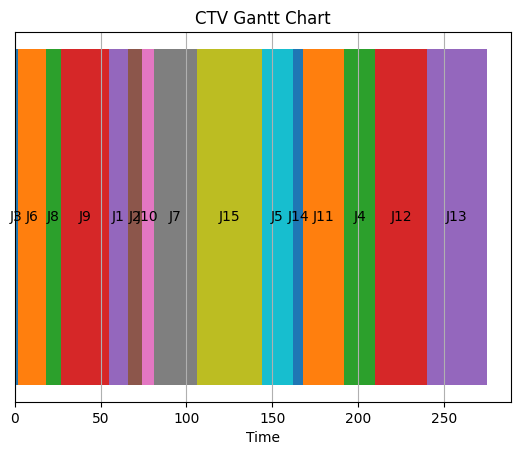

,Job,Start,Duration,Completion
0,3,0,2,2
1,6,2,16,18
2,8,18,9,27
3,9,27,28,55
4,1,55,11,66
5,2,66,8,74
6,10,74,7,81
7,7,81,25,106
8,15,106,38,144
9,5,144,18,162


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

schedule = ctv_result["Schedule"]

start = 0
rows = []

for job in schedule:
    j = job - 1
    duration = p[j]
    completion = start + duration

    rows.append([job, start, duration, completion])

    plt.barh(0, duration, left=start)
    plt.text(start + duration/2, 0, f"J{job}", ha="center", va="center")

    start = completion

plt.title("CTV Gantt Chart")
plt.xlabel("Time")
plt.yticks([])
plt.grid(axis="x")
plt.show()

ctv_gantt = pd.DataFrame(rows, columns=["Job", "Start", "Duration", "Completion"])
display(ctv_gantt)

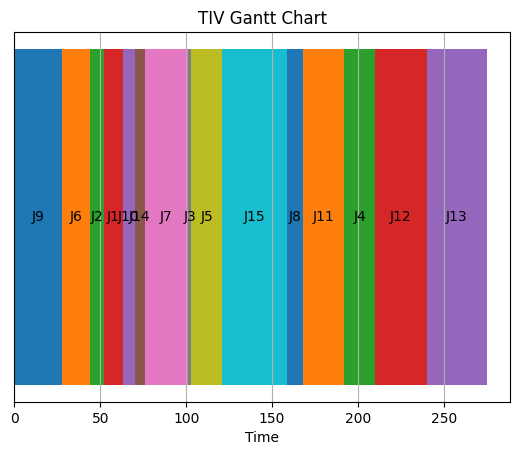

,Job,Start,Duration,Completion
0,9,0,28,28
1,6,28,16,44
2,2,44,8,52
3,1,52,11,63
4,10,63,7,70
5,14,70,6,76
6,7,76,25,101
7,3,101,2,103
8,5,103,18,121
9,15,121,38,159


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

schedule = tiv_result["Schedule"]

start = 0
rows = []

for job in schedule:
    j = job - 1
    duration = p[j]
    completion = start + duration

    rows.append([job, start, duration, completion])

    plt.barh(0, duration, left=start)
    plt.text(start + duration/2, 0, f"J{job}", ha="center", va="center")

    start = completion

plt.title("TIV Gantt Chart")
plt.xlabel("Time")
plt.yticks([])
plt.grid(axis="x")
plt.show()

tiv_gantt = pd.DataFrame(rows, columns=["Job", "Start", "Duration", "Completion"])
display(tiv_gantt)

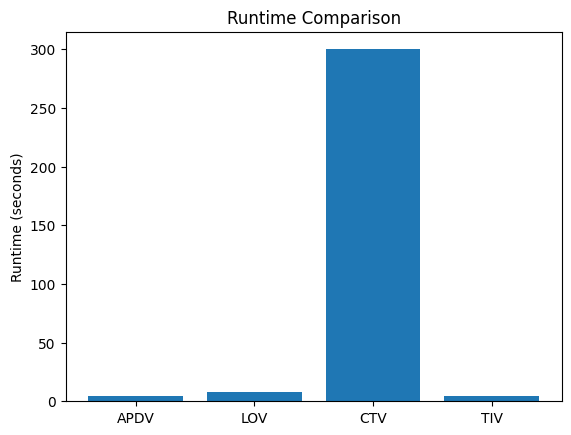

In [ ]:
import matplotlib.pyplot as plt

plt.bar(
    df_results["Formulation"],
    df_results["Runtime"]
)

plt.ylabel("Runtime (seconds)")
plt.title("Runtime Comparison")
plt.show()